# Convolutional Neural Networks

## Project: Write an Algorithm for Landmark Classification

### A simple app

In this notebook we build a very simple app that uses our exported model.

> <img src="static_images/icons/noun-info-2558213.png" alt="?" style="width:25px"/> Note how we are not importing anything from our source code (we do not use any module from the ``src`` directory). This is because the exported model, differently from the model weights, is a standalone serialization of our model and therefore it does not need anything else. You can ship that file to anybody, and as long as they can import ``torch``, they will be able to use your model. This is very important for releasing pytorch models to production.

In [1]:
from ipywidgets import VBox, Button, FileUpload, Output, Label
from PIL import Image
from IPython.display import display
import io
import numpy as np
import torchvision
import torchvision.transforms as T
import torch

# Decide which model you want to use among the ones exported
learn_inf = torch.jit.load("checkpoints/transfer_exported.pt", map_location="cpu").eval()


def predict_top_k(img, k=5):
    """Return the k most likely (landmark_name, probability) pairs for a PIL image."""
    # The exported model handles resizing, cropping and normalization itself;
    # it only needs a float tensor in [0, 1] with 3 channels
    timg = T.ToTensor()(img.convert("RGB")).unsqueeze_(0)

    with torch.inference_mode():
        softmax = learn_inf(timg).cpu().numpy().squeeze()

    idxs = np.argsort(softmax)[::-1][:k]
    return [(learn_inf.class_names[i], float(softmax[i])) for i in idxs]


def get_uploaded_bytes(upload):
    """Bytes of the last uploaded file (supports ipywidgets 7 and 8)."""
    if hasattr(upload, "data"):  # ipywidgets 7
        return bytes(upload.data[-1]) if upload.data else None
    value = upload.value  # ipywidgets 8: tuple of dicts with a 'content' memoryview
    return bytes(value[-1]["content"]) if value else None


def on_click_classify(change):

    content = get_uploaded_bytes(btn_upload)

    # Let's clear the previous output (if any)
    out_pl.clear_output()

    if content is None:
        with out_pl:
            print("Please upload an image first.")
        return

    # Load image that has been uploaded
    img = Image.open(io.BytesIO(content))
    img.load()

    # Display the image
    with out_pl:

        ratio = img.size[0] / img.size[1]
        c = img.copy()
        c.thumbnail([ratio * 200, 200])
        display(c)

    # Calling the model
    for label, (landmark_name, p) in zip(labels, predict_top_k(img)):
        label.value = f"{landmark_name} (prob: {p:.2f})"


# Putting back btn_upload to a widget for next cell
btn_upload = FileUpload(accept="image/*", multiple=False)

btn_run = Button(description="Classify")
btn_run.on_click(on_click_classify)

labels = []
for _ in range(5):
    labels.append(Label())

out_pl = Output()
out_pl.clear_output()

wgs = [Label("Please upload a picture of a landmark"), btn_upload, btn_run, out_pl]
wgs.extend(labels)

VBox(wgs)

### Classify a new photo (saved in the notebook)

Widget outputs are not always stored when the notebook is saved. The next cell classifies a photo that is **not** part of the training or test sets and shows it with its top-5 predictions as a regular, saved output.

Put your own landmark photo (for example, one you took yourself or downloaded from the web) at `app_images/my_landmark.jpg`, or upload one with the widget above and then run the cell.

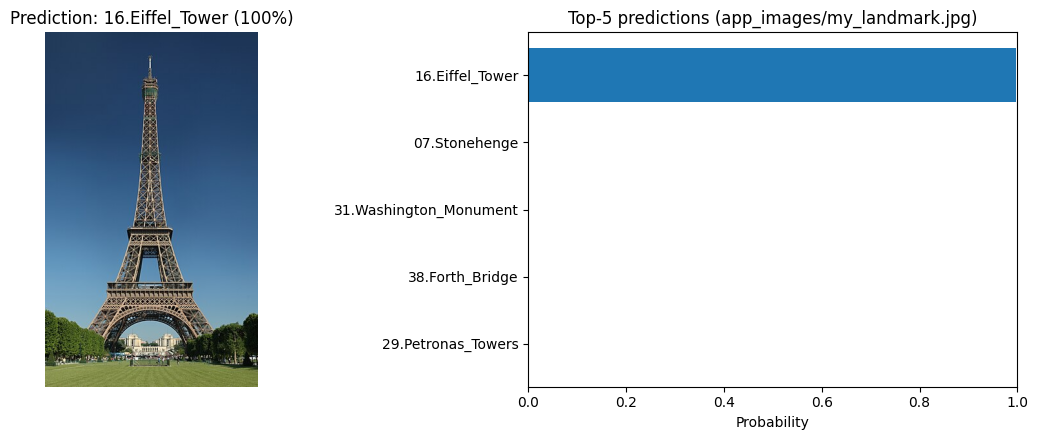

16.Eiffel_Tower: 0.997
07.Stonehenge: 0.002
31.Washington_Monument: 0.001
38.Forth_Bridge: 0.000
29.Petronas_Towers: 0.000


In [2]:
from pathlib import Path
import matplotlib.pyplot as plt

image_path = Path("app_images/my_landmark.jpg")  # a photo NOT in landmark_images/

if image_path.is_file():
    img, source = Image.open(image_path), str(image_path)
elif get_uploaded_bytes(btn_upload) is not None:
    img, source = Image.open(io.BytesIO(get_uploaded_bytes(btn_upload))), "uploaded image"
else:
    raise FileNotFoundError(
        f"Add a landmark photo at '{image_path}' or upload one with the widget above."
    )
img.load()

predictions = predict_top_k(img)

fig, (ax_img, ax_bar) = plt.subplots(1, 2, figsize=(12, 4.5), gridspec_kw={"width_ratios": [1.2, 1]})
ax_img.imshow(img.convert("RGB"))
ax_img.set_title(f"Prediction: {predictions[0][0]} ({predictions[0][1]:.0%})")
ax_img.axis("off")

names, probs = zip(*predictions)
ax_bar.barh(range(len(names))[::-1], probs, color="tab:blue")
ax_bar.set_yticks(range(len(names))[::-1], names)
ax_bar.set_xlim(0, 1)
ax_bar.set_xlabel("Probability")
ax_bar.set_title(f"Top-5 predictions ({source})")
plt.tight_layout()
plt.show()

for name, prob in predictions:
    print(f"{name}: {prob:.3f}")

## (optional) Taking it to the next level

You can run this notebook as a standalone app on your computer by following these steps:

1. Download this notebook in a directory on your machine
2. Download the model export (for example, ``checkpoints/transfer_exported.pt``) in a subdirectory called ``checkpoints`` within the directory where you save the app.ipynb notebook
3. Install voila if you don't have it already (``pip install voila``)
4. Run your app: ``voila app.ipynb --show_tracebacks=True``
5. Customize your notebook to make your app prettier and rerun voila

You can also deploy this app as a website using Binder: https://voila.readthedocs.io/en/stable/deploy.html#deployment-on-binder